# 07 · Time-series analysis and order-volume forecasting
**Owner:** P1 (Weather Data & Forecasting) · **Tasks:** T04 data preparation, T05 forecasting models, T06 evaluation ·
**Rubric:** Review 2, Method 2 (time series): preparation and implementation (2), evaluation and interpretation (3)

**Question.** Can next week's daily order volume be forecast, and does knowing the weather improve the forecast?

**Data.** Real daily weather for Coimbatore from Open-Meteo (`data/raw/weather.csv`, see `docs/dataset.md`) joined to the
*synthetic* daily order counts from the generator. Order counts are synthetic by design, so the results below describe how well
each method recovers the documented generator rules; they are not evidence about a real restaurant.

**Plan.** 1) prepare and test the series, 2) fit baselines and three model families, 3) compare them with a rolling-origin
backtest, 4) check residuals, segment errors (rainy vs dry, Fri–Sun vs Mon–Thu) and translate the error into a planning buffer.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import forecast as F
import plotstyle as S
S.apply()

RES = ROOT / "results"; RES.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(RES / f"{name}.png", dpi=160, bbox_inches="tight")

# ---- configuration -------------------------------------------------------------------------
WEATHER_CSV = ROOT / "data/raw/weather.csv"
ORDERS_CSV  = ROOT / "data/raw/daily_orders.csv"   # P2's final orders file
INITIAL, HORIZON, STEP = 180, 7, 7    # backtest: first 180 days to train, then 7-day forecasts every 7 days
TEST_DAYS = 56                        # static hold-out: last 8 weeks

## T04 · Data preparation
### 1. Load and check the data

In [2]:
df = F.load_daily(WEATHER_CSV, ORDERS_CSV)
assert df["order_count"].notna().all(), "orders missing for some weather days"
display(F.data_quality(df).to_frame("value"))
display(df[["order_count", "precip_mm", "temp_max_c", "is_rainy", "heavy_rain", "is_hot", "dow", "regime"]].head())

,value
days,1097
start,2023-09-24
end,2026-09-24
missing_order_days,0
missing_weather_cells,0
min_orders,61.0
max_orders,384.0


,order_count,precip_mm,temp_max_c,is_rainy,heavy_rain,is_hot,dow,regime
date,,,,,,,,
2023-09-24,248.0,8.2,31.2,1,0,0,6,rainy
2023-09-25,117.0,2.8,30.0,1,0,0,0,rainy
2023-09-26,160.0,6.7,30.5,1,0,0,1,rainy
2023-09-27,166.0,9.6,30.8,1,0,0,2,rainy
2023-09-28,162.0,1.9,29.9,0,0,0,3,normal


### 2. The series and how weather relates to it
Blue dots mark rainy days (≥ 2.5 mm). The 7-day mean shows there is no visible trend; the day-to-day movement is weekday
pattern, weather and noise.

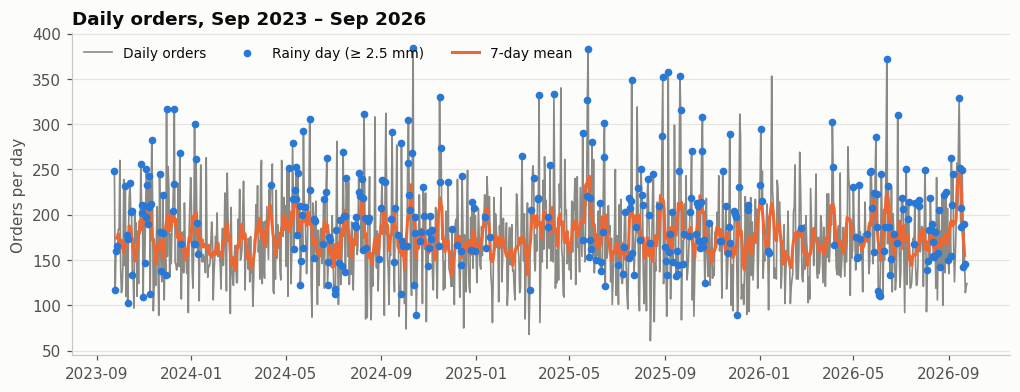

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(df.index, df["order_count"], color=S.C["gray"], lw=1.1, label="Daily orders")
r = df[df["is_rainy"] == 1]
ax.scatter(r.index, r["order_count"], s=16, color=S.C["blue"], zorder=3, label="Rainy day (≥ 2.5 mm)")
ax.plot(df.index, df["order_count"].rolling(7, center=True).mean(), color=S.C["orange"], lw=2, label="7-day mean")
ax.set_ylabel("Orders per day"); ax.set_title("Daily orders, Sep 2023 – Sep 2026")
ax.legend(ncol=3, loc="upper left")
save(fig, "fig01_series"); plt.show()

,days,mean,median,std
regime,,,,
hot,265,171.7,166.0,42.0
normal,503,161.2,156.0,44.5
rainy,329,203.1,198.0,54.7


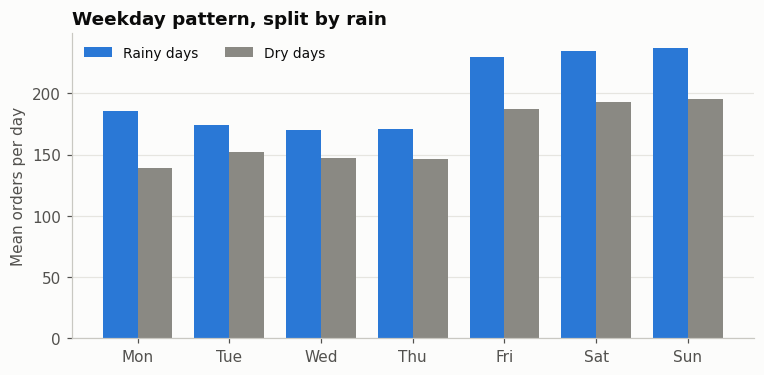

In [4]:
g = df.groupby("regime")["order_count"].agg(days="count", mean="mean", median="median", std="std").round(1)
display(g)

pv = df.assign(rain=np.where(df["is_rainy"] == 1, "rainy", "dry")).pivot_table(index="dow", columns="rain", values="order_count", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(7); w = 0.38
ax.bar(x - w/2, pv["rainy"], w, color=S.C["blue"], label="Rainy days")
ax.bar(x + w/2, pv["dry"], w, color=S.C["gray"], label="Dry days")
ax.set_xticks(x, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.set_ylabel("Mean orders per day")
ax.set_title("Weekday pattern, split by rain"); ax.legend(ncol=2, loc="upper left")
save(fig, "fig02_weekday_rain"); plt.show()

### 3. Stationarity
ADF tests the null of a unit root; KPSS tests the null of stationarity. Reading them together: ADF rejecting *and* KPSS not
rejecting is the clean "stationary" result. A stationary series needs no differencing, so the models below use `d = 0`.

In [5]:
st = F.stationarity_tests(df["order_count"])
display(st.round(4))

,test,statistic,p_value,reading
0,ADF,-6.2887,0.0,unit root rejected -> stationary
1,KPSS (level),0.0439,0.1,stationary not rejected


### 4. Seasonal decomposition
Additive decomposition with a weekly period (7). Three years are available, so a yearly component could be estimated, but the generator has no yearly term, so none is
included; the weekly period and the festival flag carry the calendar structure.

Weekly seasonal strength: 0.30 (0 = none, 1 = pure seasonality)
Correlation of the remainder with same-day rainfall: 0.23


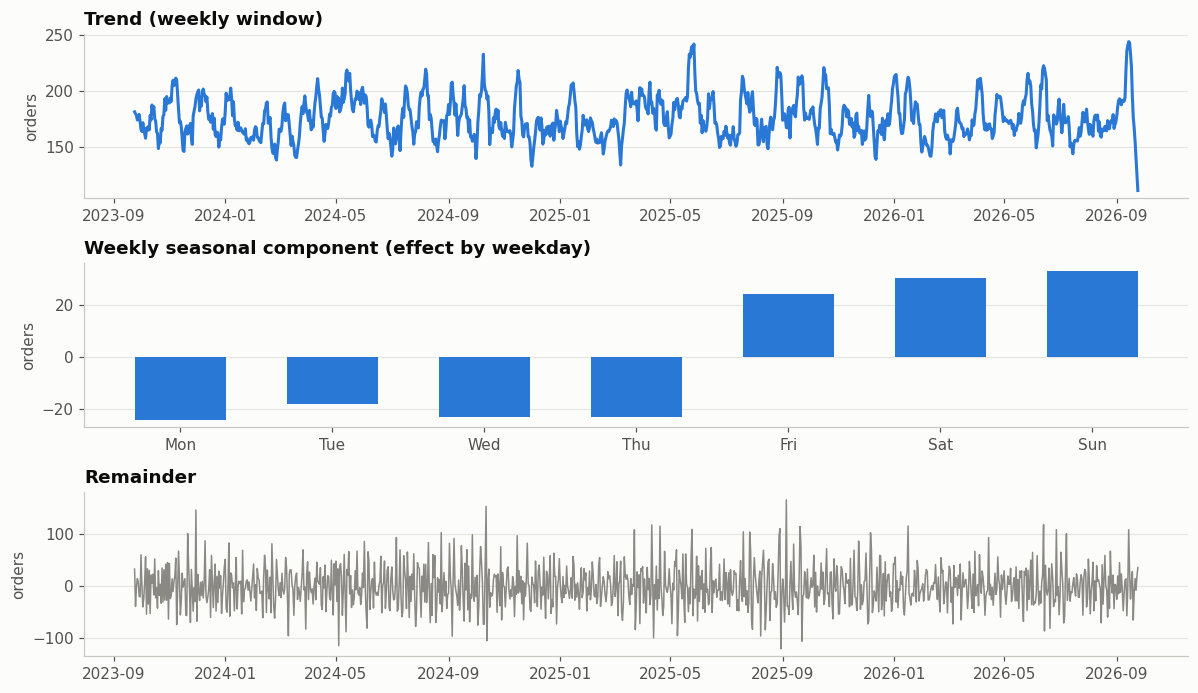

In [6]:
dec = F.decompose(df["order_count"], period=7)
fs = F.weekly_strength(dec)
rem_vs_rain = np.corrcoef(dec.resid.dropna(), df.loc[dec.resid.dropna().index, "precip_mm"])[0, 1]
print(f"Weekly seasonal strength: {fs:.2f} (0 = none, 1 = pure seasonality)")
print(f"Correlation of the remainder with same-day rainfall: {rem_vs_rain:.2f}")

fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), sharex=False)
axes[0].plot(dec.trend.index, dec.trend, color=S.C["blue"]); axes[0].set_title("Trend (weekly window)")
sea = dec.seasonal.groupby(dec.seasonal.index.dayofweek).mean()
axes[1].bar(range(7), sea.values, color=S.C["blue"], width=0.6)
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_title("Weekly seasonal component (effect by weekday)")
axes[2].plot(dec.resid.index, dec.resid, color=S.C["gray"], lw=1); axes[2].set_title("Remainder")
for a in axes: a.set_ylabel("orders")
fig.tight_layout(); save(fig, "fig03_decomposition"); plt.show()

### 5. Time-ordered train / test split
No shuffling: the last 8 weeks are held out. Model hyper-parameters are chosen using only the first `INITIAL` days.

train: 2023-09-24 → 2026-07-30 (1041 days)
test : 2026-07-31 → 2026-09-24 (56 days)


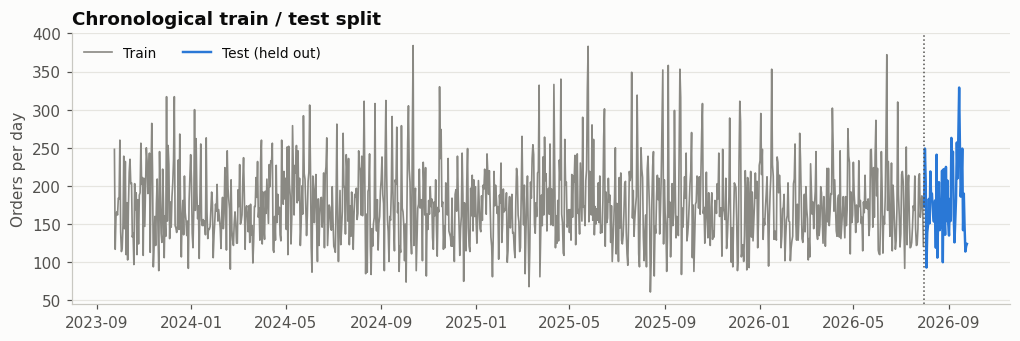

In [7]:
train, test = F.time_split(df, TEST_DAYS)
print(f"train: {train.index.min().date()} → {train.index.max().date()} ({len(train)} days)")
print(f"test : {test.index.min().date()} → {test.index.max().date()} ({len(test)} days)")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(train.index, train["order_count"], color=S.C["gray"], lw=1.1, label="Train")
ax.plot(test.index, test["order_count"], color=S.C["blue"], lw=1.6, label="Test (held out)")
ax.axvline(test.index[0], color=S.C["ink2"], lw=1, ls=":")
ax.set_ylabel("Orders per day"); ax.set_title("Chronological train / test split"); ax.legend(ncol=2, loc="upper left")
save(fig, "fig04_split"); plt.show()

## T05 · Forecasting models
| Model | What it does | Uses weather? |
|---|---|---|
| Seasonal naive | repeats the last observed week | no |
| Weekday mean | average of each weekday over the training window (stronger baseline) | no |
| SARIMAX (no weather) | day-of-week dummies + festival flag + ARMA errors | no |
| SARIMAX (weather) | the same, plus rain, heavy-rain and hot-day flags | yes |
| SARIMAX log (weather) | as above on log orders (effects of rain and heat are proportional) | yes |
| Prophet (weather) | weekly seasonality + festival flag + the same three weather regressors; no yearly term | yes |

**Weather is oracle weather.** For each forecast day the model is given that day's *observed* weather. A live system would have
to use a weather forecast, so the accuracy below is an upper bound for the weather models.

In [8]:
init = df.iloc[:INITIAL]
spec_w, tab_w = F.select_sarimax_order(init, weather=True)
spec_l, tab_l = F.select_sarimax_order(init, weather=True, log=True)
spec_n, tab_n = F.select_sarimax_order(init, weather=False)
for name, tab in [("SARIMAX (weather)", tab_w), ("SARIMAX log (weather)", tab_l), ("SARIMAX (no weather)", tab_n)]:
    print(name, "- three lowest AIC candidates (chosen on the first", INITIAL, "days only)")
    display(tab.head(3).round(1))

SARIMAX (weather) - three lowest AIC candidates (chosen on the first 180 days only)


,order,seasonal,aic,bic
0,"(1, 0, 0)","(1, 0, 0, 7)",1747.9,1792.0
1,"(0, 0, 0)","(1, 0, 0, 7)",1758.4,1799.4
2,"(0, 0, 1)","(1, 0, 0, 7)",1759.2,1803.4


SARIMAX log (weather) - three lowest AIC candidates (chosen on the first 180 days only)


,order,seasonal,aic,bic
0,"(0, 0, 1)","(0, 0, 0, 0)",-31.4,10.0
1,"(1, 0, 0)","(0, 0, 0, 0)",-30.3,11.2
2,"(1, 0, 1)","(0, 0, 0, 0)",-29.4,15.2


SARIMAX (no weather) - three lowest AIC candidates (chosen on the first 180 days only)


,order,seasonal,aic,bic
0,"(2, 0, 0)","(1, 0, 0, 7)",1778.2,1815.9
1,"(1, 0, 1)","(1, 0, 0, 7)",1778.5,1816.3
2,"(1, 0, 0)","(1, 0, 0, 7)",1779.2,1813.8


In [9]:
models = {
    "Seasonal naive":        F.seasonal_naive,
    "Weekday mean":          F.weekday_mean,
    "SARIMAX (no weather)":  F.make_sarimax(spec_n),
    "SARIMAX (weather)":     F.make_sarimax(spec_w),
    "SARIMAX log (weather)": F.make_sarimax(spec_l),
    "Prophet (weather)":     F.make_prophet(weather=True),
}
fc = F.rolling_origin(df, models, initial=INITIAL, horizon=HORIZON, step=STEP)
fc.to_csv(RES / "backtest_forecasts.csv", index=False)
print(f"{fc['date'].nunique()} forecast days x {len(models)} models; first forecast day {fc['date'].min():%Y-%m-%d}")

11:20:55 - cmdstanpy - INFO - Chain [1] start processing


11:20:56 - cmdstanpy - INFO - Chain [1] done processing


  fold 5/131 (origin 2024-04-19)


  fold 10/131 (origin 2024-05-24)


  fold 15/131 (origin 2024-06-28)


  fold 20/131 (origin 2024-08-02)


... (19 outputs left out)

  fold 120/131 (origin 2026-07-03)


  fold 125/131 (origin 2026-08-07)


  fold 130/131 (origin 2026-09-11)


  fold 131/131 (origin 2026-09-18)
917 forecast days x 6 models; first forecast day 2024-03-22


### Forecast versus actual, last 8 weeks of the backtest

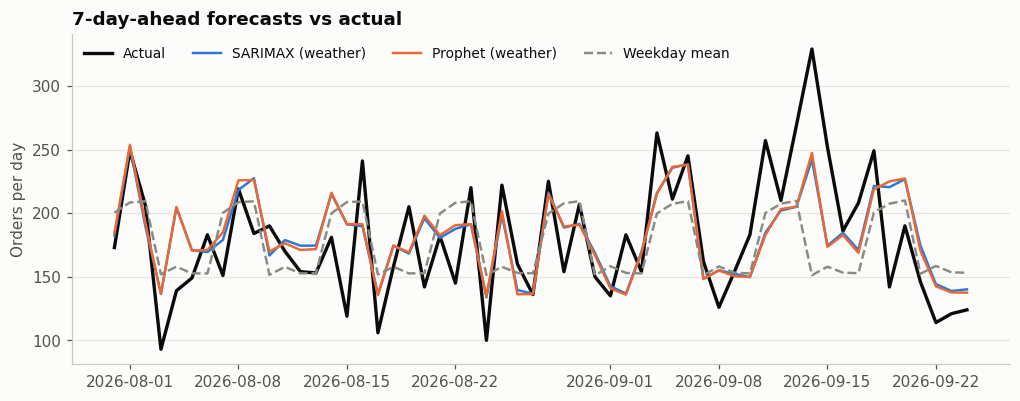

In [10]:
last = fc["date"].sort_values().unique()[-TEST_DAYS:]
fig, ax = plt.subplots(figsize=(11, 3.9))
act = fc[fc["model"] == "SARIMAX (weather)"].set_index("date").loc[last]
ax.plot(act.index, act["y"], color=S.C["ink"], lw=2.2, label="Actual")
for name, col, ls in [("SARIMAX (weather)", S.C["blue"], "-"), ("Prophet (weather)", S.C["orange"], "-"), ("Weekday mean", S.C["gray"], "--")]:
    p = fc[fc["model"] == name].set_index("date").loc[last]
    ax.plot(p.index, p["yhat"], color=col, lw=1.6, ls=ls, label=name)
ax.set_ylabel("Orders per day"); ax.set_title("7-day-ahead forecasts vs actual")
ax.legend(ncol=4, loc="upper left")
save(fig, "fig05_forecast_vs_actual"); plt.show()

## T06 · Evaluation and interpretation
### 1. Accuracy over the whole backtest
MAE and RMSE are in orders per day; MAPE is relative to actual orders. `cover80_%` is the share of days that fell inside the
model's own 80 % prediction interval (should be near 80).

,n,MAE,RMSE,MAPE_%,bias,cover80_%,"MAE vs weekday mean, %"
model,,,,,,,
SARIMAX log (weather),917,30.74,39.08,18.57,1.30,80.15,-10.21
Prophet (weather),917,30.91,39.33,18.71,0.51,81.03,-9.71
SARIMAX (weather),917,31.02,39.54,18.66,1.67,80.92,-9.39
SARIMAX (no weather),917,33.76,43.39,20.46,1.52,81.35,-1.40
Weekday mean,917,34.24,44.38,20.78,1.31,NaN,0.00
Seasonal naive,917,47.98,61.31,28.86,0.11,NaN,40.14


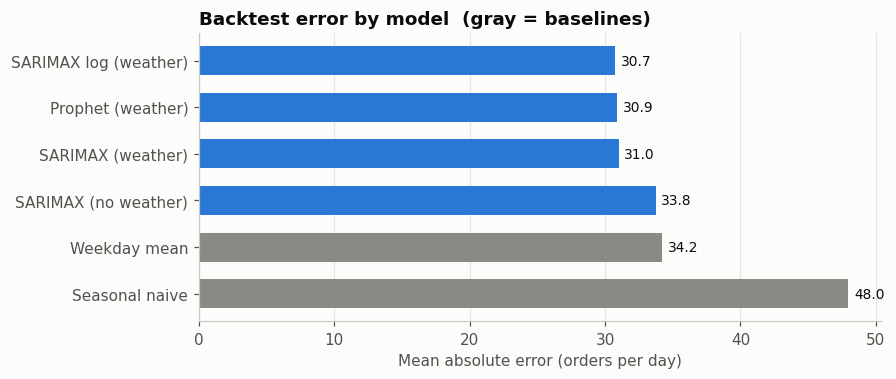

In [11]:
M = F.metrics(fc).sort_values("MAE")
base = M.loc["Weekday mean", "MAE"]
M["MAE vs weekday mean, %"] = (M["MAE"] / base - 1) * 100
display(M.round(2))
M.round(3).to_csv(RES / "metrics_overall.csv")

fig, ax = plt.subplots(figsize=(8, 3.4))
order = M.index[::-1]
cols = [S.C["gray"] if m in ("Seasonal naive", "Weekday mean") else S.C["blue"] for m in order]
bars = ax.barh(order, M.loc[order, "MAE"], color=cols, height=0.62)
for b, v in zip(bars, M.loc[order, "MAE"]):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", color=S.C["ink"], fontsize=9)
ax.set_xlabel("Mean absolute error (orders per day)"); ax.set_title("Backtest error by model  (gray = baselines)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
save(fig, "fig06_mae_by_model"); plt.show()

### 2. Are the differences real?
Paired bootstrap over forecast days: the interval is for `MAE(a) − MAE(b)`. Negative means `a` is better; an interval that
includes 0 means the data cannot separate the two.

In [12]:
best_model = M.index[0]
pairs = [
    (best_model, "Weekday mean"),
    (best_model, "Seasonal naive"),
    ("SARIMAX (weather)", "SARIMAX (no weather)"),
    ("Prophet (weather)", "SARIMAX (weather)"),
    ("SARIMAX log (weather)", "SARIMAX (weather)"),
]
seen, rows = set(), []
for a, b in pairs:
    if a == b or (a, b) in seen: continue
    seen.add((a, b)); rows.append(F.paired_bootstrap_mae_diff(fc, a, b))
B = pd.DataFrame(rows)
B["ci95_low"] = B["ci95"].map(lambda t: t[0]); B["ci95_high"] = B["ci95"].map(lambda t: t[1])
B["separable"] = np.where((B["ci95_low"] > 0) | (B["ci95_high"] < 0), "yes", "no")
B = B.drop(columns="ci95")
display(B.round(2)); B.round(3).to_csv(RES / "bootstrap_comparisons.csv", index=False)

,a,b,mae_diff,share_boot_a_better,ci95_low,ci95_high,separable
0,SARIMAX log (weather),Weekday mean,-3.49,1.00,-4.70,-2.32,yes
1,SARIMAX log (weather),Seasonal naive,-17.23,1.00,-19.55,-15.01,yes
2,SARIMAX (weather),SARIMAX (no weather),-2.73,1.00,-3.86,-1.60,yes
3,Prophet (weather),SARIMAX (weather),-0.11,0.76,-0.42,0.19,no
4,SARIMAX log (weather),SARIMAX (weather),-0.28,0.97,-0.59,0.01,no


### 3. Where does the error come from? Rainy vs dry, Fri–Sun vs Mon–Thu

,,n,MAE,MAPE_%,bias
model,rain,,,,
Seasonal naive,dry,633,45.26,29.73,-9.26
Weekday mean,dry,633,31.98,22.03,-9.30
SARIMAX (no weather),dry,633,31.13,21.43,-8.90
SARIMAX (weather),dry,633,29.24,18.84,2.53
SARIMAX log (weather),dry,633,29.30,18.96,2.00
Prophet (weather),dry,633,29.28,19.01,1.02
Seasonal naive,rainy,284,54.02,26.90,20.98
Weekday mean,rainy,284,39.26,18.00,24.94
SARIMAX (no weather),rainy,284,39.60,18.29,24.76


n    MAE  MAPE_%  bias
model                 day_type                          
Seasonal naive        Fri-Sun   393  55.68   28.33  0.27
                      Mon-Thu   524  42.20   29.25 -0.01
Weekday mean          Fri-Sun   393  39.61   19.88  3.16
                      Mon-Thu   524  30.21   21.45 -0.09
SARIMAX (no weather)  Fri-Sun   393  39.50   19.84  3.46
                      Mon-Thu   524  29.45   20.92  0.07
SARIMAX (weather)     Fri-Sun   393  35.73   17.86  4.22
                      Mon-Thu   524  27.49   19.26 -0.24
SARIMAX log (weather) Fri-Sun   393  35.55   17.88  2.98
                      Mon-Thu   524  27.14   19.08  0.04
Prophet (weather)     Fri-Sun   393  35.87   18.13  2.30
                      Mon-Thu   524  27.19   19.15 -0.83

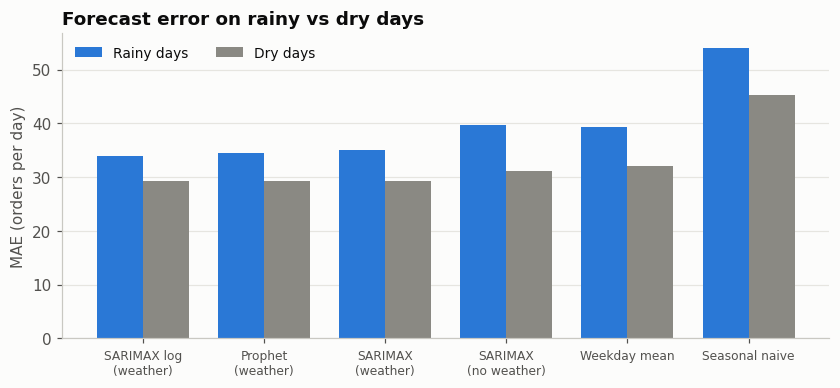

In [13]:
fcx = F.add_context(fc, df)
seg_rain = F.metrics(fcx, by=["rain"])
seg_day = F.metrics(fcx, by=["day_type"])
display(seg_rain[["n", "MAE", "MAPE_%", "bias"]].round(2))
display(seg_day[["n", "MAE", "MAPE_%", "bias"]].round(2))
pd.concat({"rain": seg_rain, "day_type": seg_day}).round(3).to_csv(RES / "metrics_by_segment.csv")

pr = seg_rain["MAE"].unstack("rain").loc[M.index]
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(pr)); w = 0.38
ax.bar(x - w/2, pr["rainy"], w, color=S.C["blue"], label="Rainy days")
ax.bar(x + w/2, pr["dry"], w, color=S.C["gray"], label="Dry days")
ax.set_xticks(x, [m.replace(" (", "\n(") for m in pr.index], fontsize=8)
ax.set_ylabel("MAE (orders per day)"); ax.set_title("Forecast error on rainy vs dry days"); ax.legend(ncol=2, loc="upper left")
save(fig, "fig07_error_rain_dry"); plt.show()

### 4. Residual checks for the best model
If the model has captured the systematic structure, the out-of-sample errors should show no autocorrelation
(Ljung–Box p > 0.05), be centred near zero, and not depend on the rain regime.

Best model: SARIMAX log (weather)
Ljung-Box p-values: {7: 0.463, 14: 0.382}
Residual mean 1.3, std 39.1


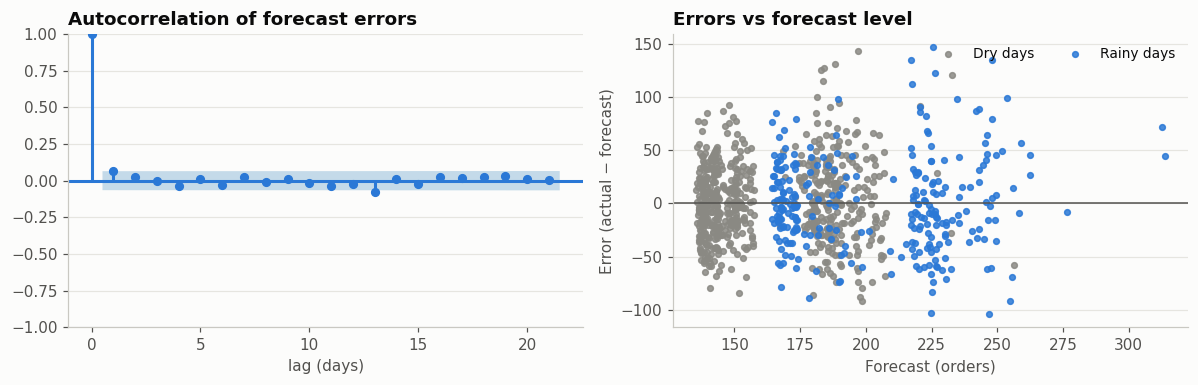

,days,mean,std
regime,,,
hot,216,3.0,37.6
normal,417,1.5,36.6
rainy,284,-0.3,43.5


In [14]:
from statsmodels.graphics.tsaplots import plot_acf
diag = F.residual_diagnostics(fc, best_model, lags=(7, 14))
print(f"Best model: {best_model}")
print("Ljung-Box p-values:", {k: round(v, 3) for k, v in diag["ljung_box_p"].items()})
print(f"Residual mean {diag['resid_mean']:.1f}, std {diag['resid_std']:.1f}")

r = fcx[fcx["model"] == best_model].sort_values("date")
res = (r["y"] - r["yhat"]).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(res, lags=21, ax=axes[0], color=S.C["blue"], vlines_kwargs={"colors": S.C["blue"]}, alpha=0.05)
axes[0].set_title("Autocorrelation of forecast errors"); axes[0].set_xlabel("lag (days)")
for name, col in [("dry", S.C["gray"]), ("rainy", S.C["blue"])]:
    s = r["rain"] == name
    axes[1].scatter(r.loc[s, "yhat"], res[s.to_numpy()], s=14, color=col, label=name.capitalize() + " days", alpha=0.85)
axes[1].axhline(0, color=S.C["ink2"], lw=1)
axes[1].set_xlabel("Forecast (orders)"); axes[1].set_ylabel("Error (actual − forecast)")
axes[1].set_title("Errors vs forecast level"); axes[1].legend(ncol=2)
fig.tight_layout(); save(fig, "fig08_residuals"); plt.show()

display(r.assign(err=res).groupby("regime")["err"].agg(days="count", mean="mean", std="std").round(1))

### 5. Longer horizon: fit once, forecast the 8-week hold-out

In [15]:
hold = F.static_holdout(df, models, test_days=TEST_DAYS)
H = F.metrics(hold).sort_values("MAE")
display(H.round(2)); H.round(3).to_csv(RES / "metrics_static_holdout.csv")

,n,MAE,RMSE,MAPE_%,bias,cover80_%
model,,,,,,
SARIMAX (weather),56,29.40,36.63,17.35,-2.08,83.93
Prophet (weather),56,29.45,36.65,17.48,-3.19,85.71
SARIMAX log (weather),56,29.49,36.61,17.32,-1.66,82.14
SARIMAX (no weather),56,32.25,42.26,18.69,4.79,78.57
Weekday mean,56,32.81,44.78,18.96,3.82,NaN
Seasonal naive,56,44.38,53.78,26.57,2.12,NaN


### 6. How close to the best possible?
Because the orders are synthetic, the noise floor is known: no model can beat the generator's own expected value. The cell
below applies the multipliers documented by P2 (`docs/generator.md`) to the backtest days. **These constants are copied from the
final generator (including the festival uplift on the 41 festival days); update them if P2 changes the generator.**

In [16]:
BASE, WEEKEND, RAIN_MID, RAIN_HEAVY, HEAT, FESTIVAL = 140, 1.30, 1.20, 1.35, 1.10, 1.25
d = df.loc[fc["date"].unique()].copy()
mult = np.where(d["dow"].isin([4, 5, 6]), WEEKEND, 1.0) \
     * np.select([d["precip_mm"] >= 15, d["precip_mm"] >= 2.5], [RAIN_HEAVY, RAIN_MID], 1.0) \
     * np.where(d["temp_max_c"] >= 33, HEAT, 1.0) \
     * np.where(d["is_festival"] == 1, FESTIVAL, 1.0)
floor = pd.DataFrame({"date": d.index, "y": d["order_count"].to_numpy(), "yhat": BASE * mult, "model": "Generator expected value",
                      "lo80": np.nan, "hi80": np.nan})
floor_m = F.metrics(floor)
display(floor_m.round(2))
FLOOR_MAE = float(floor_m["MAE"].iloc[0])

,n,MAE,RMSE,MAPE_%,bias
model,,,,,
Generator expected value,917,30.45,38.81,18.34,2.03


### 7. What the forecast means for operations
The planning buffer is how far above the forecast to prepare so that 90 % of days are covered.

In [17]:
buf_all = F.planning_buffer(fc, best_model, 0.90)
buf_rain = F.planning_buffer(fcx[fcx["rain"] == "rainy"], best_model, 0.90)
buf_dry = F.planning_buffer(fcx[fcx["rain"] == "dry"], best_model, 0.90)
buf = pd.DataFrame({"all days": buf_all, "rainy days": buf_rain, "dry days": buf_dry}).T.drop(columns="q").round(1)
display(buf); buf.to_csv(RES / "planning_buffer.csv")

,buffer_orders,buffer_pct_of_forecast
all days,49.0,28.9
rainy days,51.7,25.6
dry days,47.2,30.0


## Conclusions
The text below is generated from the results above, so it stays correct if the data or the generator changes.

In [18]:
def mae(m): return float(M.loc[m, "MAE"])
w_gain = mae("SARIMAX (no weather)") - mae("SARIMAX (weather)")
b1 = B[(B["a"] == best_model) & (B["b"] == "Weekday mean")]
b2 = B[(B["a"] == "SARIMAX (weather)") & (B["b"] == "SARIMAX (no weather)")]
rain_mae, dry_mae = seg_rain.loc[(best_model, "rainy"), "MAE"], seg_rain.loc[(best_model, "dry"), "MAE"]
rr = r.assign(err=res)
rain_sd, other_sd = rr.loc[rr["rain"] == "rainy", "err"].std(), rr.loc[rr["rain"] == "dry", "err"].std()
weather_models = ["SARIMAX (weather)", "SARIMAX log (weather)", "Prophet (weather)"]
wm_sep = B[B["a"].isin(weather_models) & B["b"].isin(weather_models)]
cov = M.loc[best_model].get("cover80_%", float("nan"))
hold_best = H.index[0]
lines = [
    f"1. Best model on the rolling backtest: {best_model}, MAE {mae(best_model):.1f} orders/day "
    f"({M.loc[best_model, 'MAPE_%']:.1f}% MAPE), against {mae('Seasonal naive'):.1f} for the seasonal-naive baseline and "
    f"{mae('Weekday mean'):.1f} for the weekday-mean baseline.",
    f"2. Knowing the weather lowers SARIMAX error by {w_gain:.1f} orders/day ({w_gain / mae('SARIMAX (no weather)') * 100:.0f}%); "
    f"paired-bootstrap 95% interval for the MAE difference {b2['ci95_low'].iloc[0]:.1f} to {b2['ci95_high'].iloc[0]:.1f} "
    f"({'distinguishable from zero' if b2['separable'].iloc[0] == 'yes' else 'not distinguishable from zero with this sample'}).",
    f"3. Versus the weekday-mean baseline the best model's MAE difference is {b1['mae_diff'].iloc[0]:.1f} orders/day "
    f"(95% interval {b1['ci95_low'].iloc[0]:.1f} to {b1['ci95_high'].iloc[0]:.1f}).",
    f"4. Error on rainy days is {rain_mae:.1f} orders/day against {dry_mae:.1f} on dry days; the spread of the best model's errors is "
    f"{rain_sd:.0f} on rainy days versus {other_sd:.0f} on dry days, so rainy days are the hardest to plan for.",
    f"5. The generator's own expected value would score MAE {FLOOR_MAE:.1f}. The best model is {mae(best_model) - FLOOR_MAE:.1f} orders/day "
    f"({(mae(best_model) - FLOOR_MAE) / mae(best_model) * 100:.0f}% of its error) above that floor, "
    f"{'so nearly all remaining error is irreducible noise' if (mae(best_model) - FLOOR_MAE) / mae(best_model) < 0.15 else 'so there is still some structure a better model could capture'}.",
    f"6. Residuals: Ljung–Box p-values {', '.join(f'lag {k}: {v:.2f}' for k, v in diag['ljung_box_p'].items())} "
    f"({'no leftover autocorrelation' if min(diag['ljung_box_p'].values()) > 0.05 else 'some autocorrelation remains'}). "
    f"Prediction intervals labelled 80% covered {cov:.0f}% of days ({'close to nominal' if abs(cov - 80) <= 3 else 'narrower than nominal, so use the empirical buffer in point 8 rather than the model interval'}).",
    f"7. Model choice: the weather-aware models ({', '.join(weather_models)}) are "
    f"{'statistically indistinguishable from each other' if (wm_sep['separable'] == 'no').all() else 'not all equivalent'} on this backtest, "
    f"and the winner was picked on the same folds it is scored on, so treat the ranking among them as tentative. "
    f"On the 8-week static hold-out the lowest MAE is {H['MAE'].iloc[0]:.1f} ({hold_best}) against {H.loc['Weekday mean', 'MAE']:.1f} for the weekday-mean baseline.",
    f"8. Planning: prepare for forecast + {buf_all['buffer_orders']:.0f} orders (≈{buf_all['buffer_pct_of_forecast']:.0f}%) to cover 9 days in 10; "
    f"on rainy days the buffer is {buf_rain['buffer_orders']:.0f} orders, on dry days {buf_dry['buffer_orders']:.0f}.",
]
from IPython.display import Markdown
display(Markdown("\n\n".join(lines)))

1. Best model on the rolling backtest: SARIMAX log (weather), MAE 30.7 orders/day (18.6% MAPE), against 48.0 for the seasonal-naive baseline and 34.2 for the weekday-mean baseline.

2. Knowing the weather lowers SARIMAX error by 2.7 orders/day (8%); paired-bootstrap 95% interval for the MAE difference -3.9 to -1.6 (distinguishable from zero).

3. Versus the weekday-mean baseline the best model's MAE difference is -3.5 orders/day (95% interval -4.7 to -2.3).

4. Error on rainy days is 34.0 orders/day against 29.3 on dry days; the spread of the best model's errors is 44 on rainy days versus 37 on dry days, so rainy days are the hardest to plan for.

5. The generator's own expected value would score MAE 30.5. The best model is 0.3 orders/day (1% of its error) above that floor, so nearly all remaining error is irreducible noise.

6. Residuals: Ljung–Box p-values lag 7: 0.46, lag 14: 0.38 (no leftover autocorrelation). Prediction intervals labelled 80% covered 80% of days (close to nominal).

7. Model choice: the weather-aware models (SARIMAX (weather), SARIMAX log (weather), Prophet (weather)) are statistically indistinguishable from each other on this backtest, and the winner was picked on the same folds it is scored on, so treat the ranking among them as tentative. On the 8-week static hold-out the lowest MAE is 29.4 (SARIMAX (weather)) against 32.8 for the weekday-mean baseline.

8. Planning: prepare for forecast + 49 orders (≈29%) to cover 9 days in 10; on rainy days the buffer is 52 orders, on dry days 47.

## Limits of this analysis
* **Three years of history, no yearly term.** The generator has no seasonal-by-month effect other than weather and festivals, so the models do not include one. On real data a yearly cycle would need to be tested.
* **Festival dates are treated as known in advance** (calendar flag), which is realistic for a planning system.
* **Oracle weather.** Weather-model accuracy assumes the day's weather is known. Using a weather forecast would raise the error.
* **Synthetic orders.** The order counts follow the generator's documented rules plus negative-binomial noise. Results show how well
  the methods recover those rules, not real customer behaviour.
* **Hyper-parameters** were chosen on the first 180 days only, which keeps the backtest honest but means the chosen orders may not be optimal.
* **Shared thresholds.** The weather flags (2.5 mm, 15 mm, 33 °C) are the team's regime definitions from `docs/generator.md`.